# 02 - First cell type classifier

Goal: teach a model to guess a cell's type (`bulk_labels`) from its gene expression.

Steps: load data -> split into train and test -> train -> check how well it did.

In [1]:
# Load the tools I need
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
# Same dataset as notebook 01
adata = sc.datasets.pbmc68k_reduced()
adata

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
    var: 'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', None (.X)

## Features and labels

- `X` = the numbers the model learns from (one row per cell, one column per gene)
- `y` = the answer we want it to predict (the cell type)

This dataset is already normalized and scaled, so `adata.X` can go straight into the model.

In [3]:
X = adata.X
y = adata.obs["bulk_labels"]

print("X shape (cells, genes):", X.shape)
print("Number of cell types:", y.nunique())

X shape (cells, genes): (700, 765)
Number of cell types: 10


## Train / test split

Hold back 25% of cells. The model never sees them during training, so they give an honest score.

`stratify=y` keeps the same mix of cell types in both halves. That matters here because some types are rare (only 8 naive CD4 T cells).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print("Training cells:", X_train.shape[0])
print("Test cells:", X_test.shape[0])

Training cells: 525
Test cells: 175


## Train the model

Logistic regression is a simple, standard first model.

`class_weight="balanced"` tells it to pay extra attention to rare cell types, so it does not just learn to say "Dendritic" for everything.

In [5]:
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

## How well did it do?

Compare against a lazy baseline: always guessing the most common cell type.

In [6]:
y_pred = model.predict(X_test)

baseline = (y_test == y_train.value_counts().idxmax()).mean()
accuracy = accuracy_score(y_test, y_pred)

print(f"Baseline (always guess the most common type): {baseline:.1%}")
print(f"Model accuracy on test cells: {accuracy:.1%}")

Baseline (always guess the most common type): 34.3%
Model accuracy on test cells: 86.9%


In [7]:
# Score for each cell type
# precision = when it says this type, how often is it right?
# recall    = of the cells that really are this type, how many did it find?
# support   = how many test cells of this type there were
print(classification_report(y_test, y_pred, zero_division=0))

                              precision    recall  f1-score   support

              CD14+ Monocyte       0.81      0.94      0.87        32
                     CD19+ B       1.00      0.96      0.98        24
                       CD34+       1.00      1.00      1.00         3
             CD4+/CD25 T Reg       0.61      1.00      0.76        17
  CD4+/CD45RA+/CD25- Naive T       0.00      0.00      0.00         2
         CD4+/CD45RO+ Memory       1.00      0.20      0.33         5
                    CD56+ NK       1.00      0.75      0.86         8
            CD8+ Cytotoxic T       0.77      0.77      0.77        13
CD8+/CD45RA+ Naive Cytotoxic       1.00      0.73      0.84        11
                   Dendritic       0.96      0.90      0.93        60

                    accuracy                           0.87       175
                   macro avg       0.82      0.72      0.73       175
                weighted avg       0.89      0.87      0.86       175



## Confusion matrix

Rows = the true cell type, columns = what the model guessed. Numbers on the diagonal are correct guesses; anything off the diagonal is a mix-up.

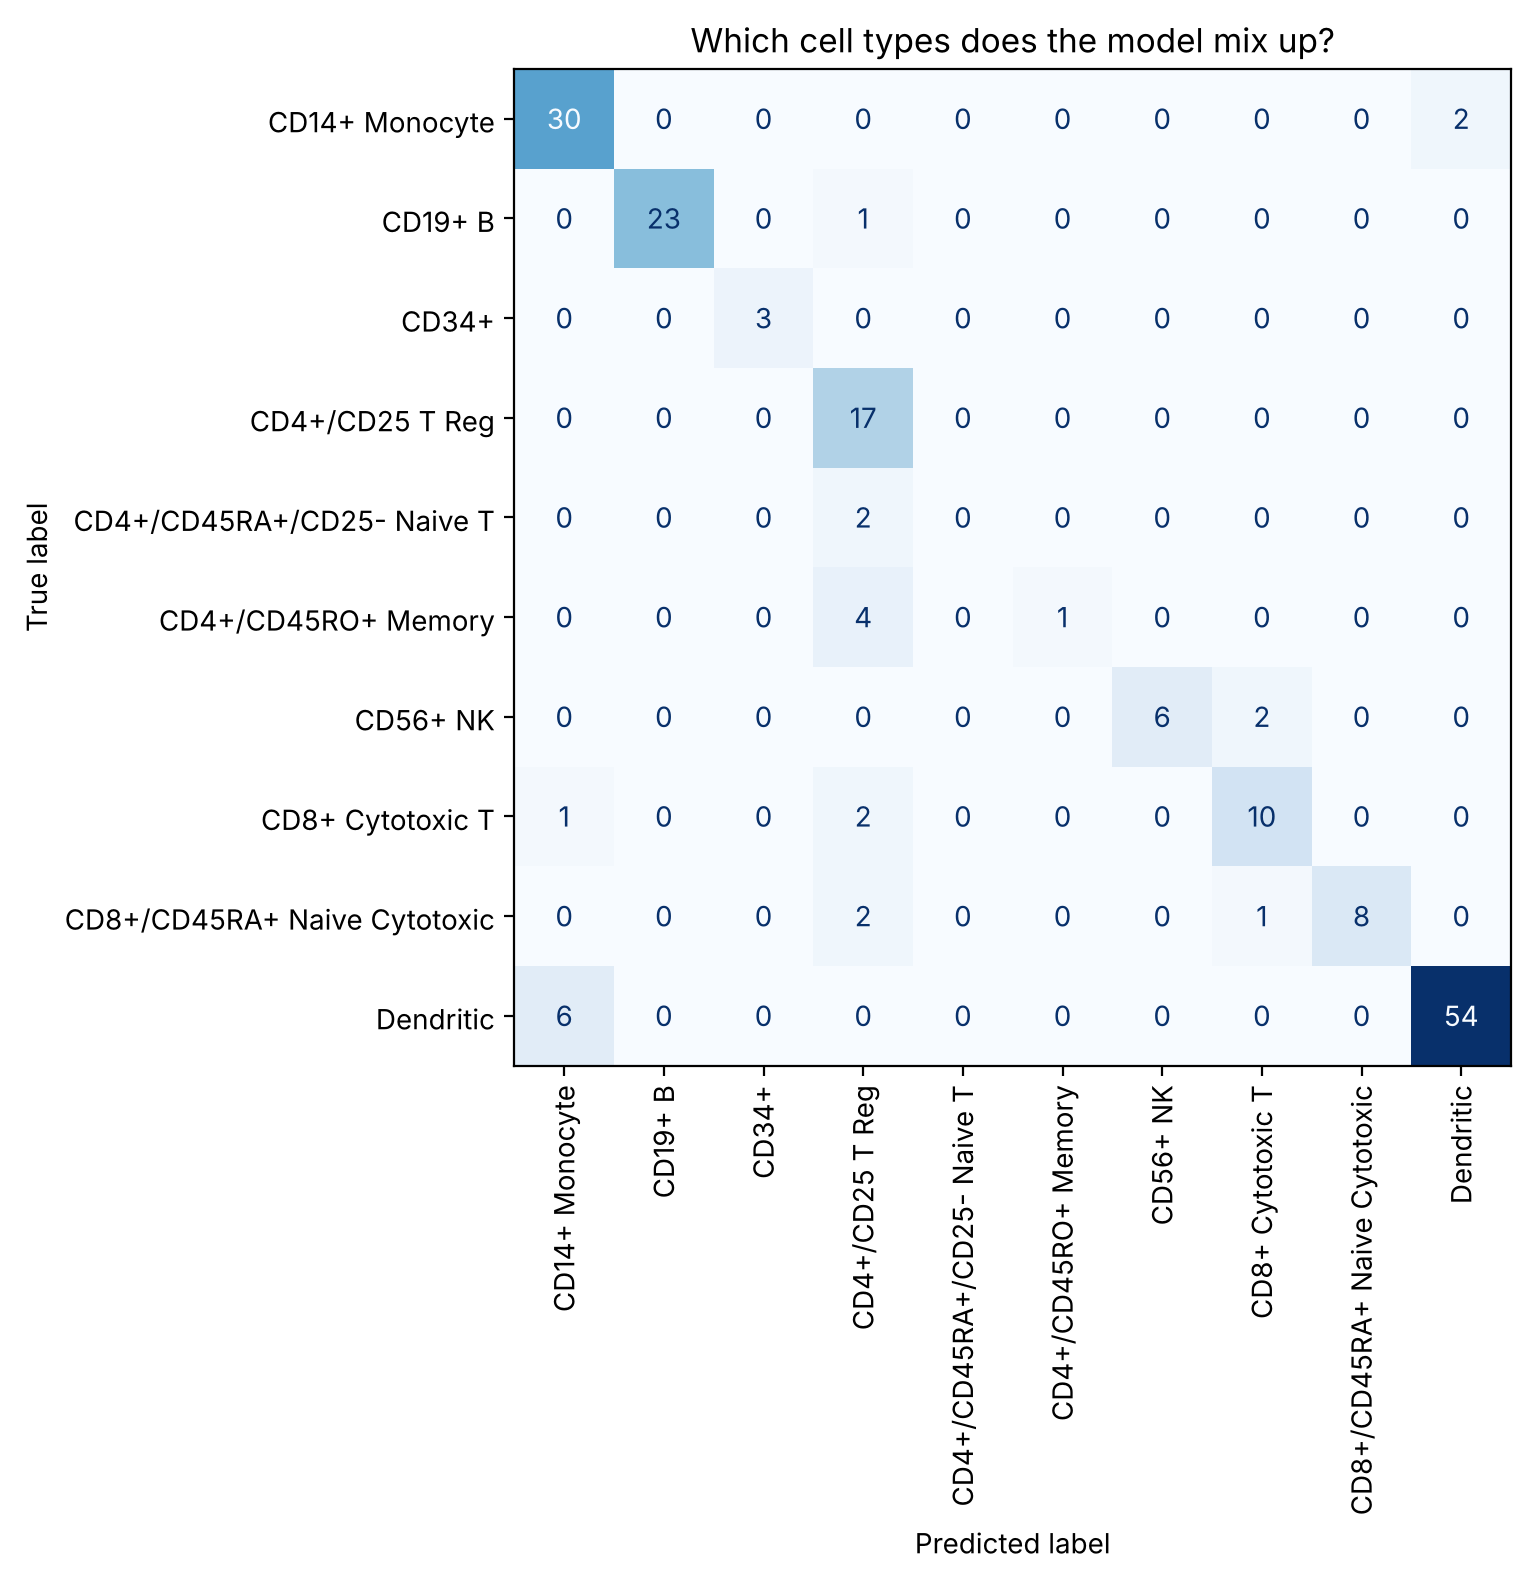

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=90, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Which cell types does the model mix up?")
plt.tight_layout()
plt.show()